In [1]:
import os
import glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2

# Set plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

In [2]:
# Dataset path configuration
DATASET_DIR = Path("/home/gabor-levai/Downloads/AI_VIS/archive (3)")

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
records = []

print(f"Scanning directory: {DATASET_DIR}")

# Traverse dataset directory recursively
for filepath in DATASET_DIR.rglob("*"):
    if filepath.is_file() and filepath.suffix.lower() in valid_extensions:
        parts_lower = [p.lower() for p in filepath.parts]
        
        # Categorize label based on folder structure or filename
        if any("real" in p for p in parts_lower):
            label = "Real"
        elif any("fake" in p for p in parts_lower):
            label = "Fake"
        else:
            label = "Unknown"
        
        try:
            with Image.open(filepath) as img:
                width, height = img.size
                channels = len(img.getbands())
            file_size_kb = filepath.stat().st_size / 1024.0
            
            records.append({
                "filepath": str(filepath),
                "filename": filepath.name,
                "label": label,
                "width": width,
                "height": height,
                "aspect_ratio": round(width / height, 3),
                "channels": channels,
                "file_size_kb": round(file_size_kb, 2)
            })
        except Exception as e:
            print(f"Skipping corrupt image {filepath}: {e}")

df = pd.DataFrame(records)
print(f"Scanned {len(df)} total images.")
df.head()

Scanning directory: /home/gabor-levai/Downloads/AI_VIS/archive (3)
Scanned 2041 total images.


,filepath,filename,label,width,height,aspect_ratio,channels,file_size_kb
0,/home/gabor-levai/Downloads/AI_VIS/archive (3)...,real_00935.jpg,Real,600,600,1.0,3,147.91
1,/home/gabor-levai/Downloads/AI_VIS/archive (3)...,real_00098.jpg,Real,600,600,1.0,3,86.55
2,/home/gabor-levai/Downloads/AI_VIS/archive (3)...,real_00596.jpg,Real,600,600,1.0,3,142.30
3,/home/gabor-levai/Downloads/AI_VIS/archive (3)...,real_00016.jpg,Real,600,600,1.0,3,62.31
4,/home/gabor-levai/Downloads/AI_VIS/archive (3)...,real_00409.jpg,Real,600,600,1.0,3,145.33


/tmp/ipykernel_9963/3916511356.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="label", palette=["#2ecc71", "#e74c3c"], ax=axes[0])


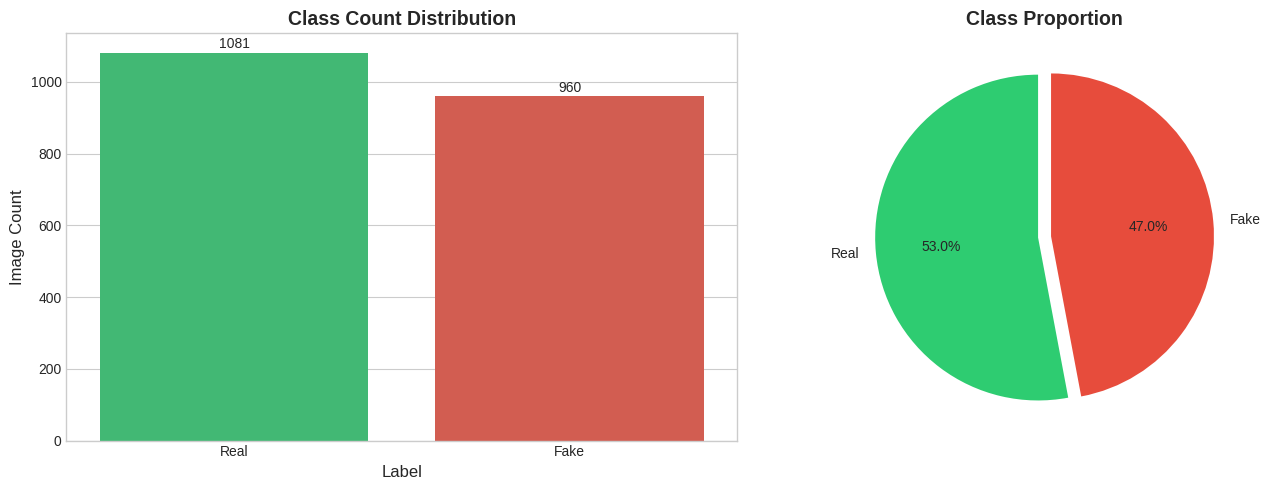

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Class count bar chart
sns.countplot(data=df, x="label", palette=["#2ecc71", "#e74c3c"], ax=axes[0])
axes[0].set_title("Class Count Distribution", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Label", fontsize=12)
axes[0].set_ylabel("Image Count", fontsize=12)

for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", 
                     (p.get_x() + p.get_width() / 2., p.get_height()), 
                     ha='center', va='center', xytext=(0, 6), textcoords='offset points')

# Class proportion pie chart
counts = df["label"].value_counts()
axes[1].pie(counts, labels=counts.index, autopct='%1.1f%%', 
             colors=["#2ecc71", "#e74c3c"], startangle=90, explode=(0.04, 0.04))
axes[1].set_title("Class Proportion", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

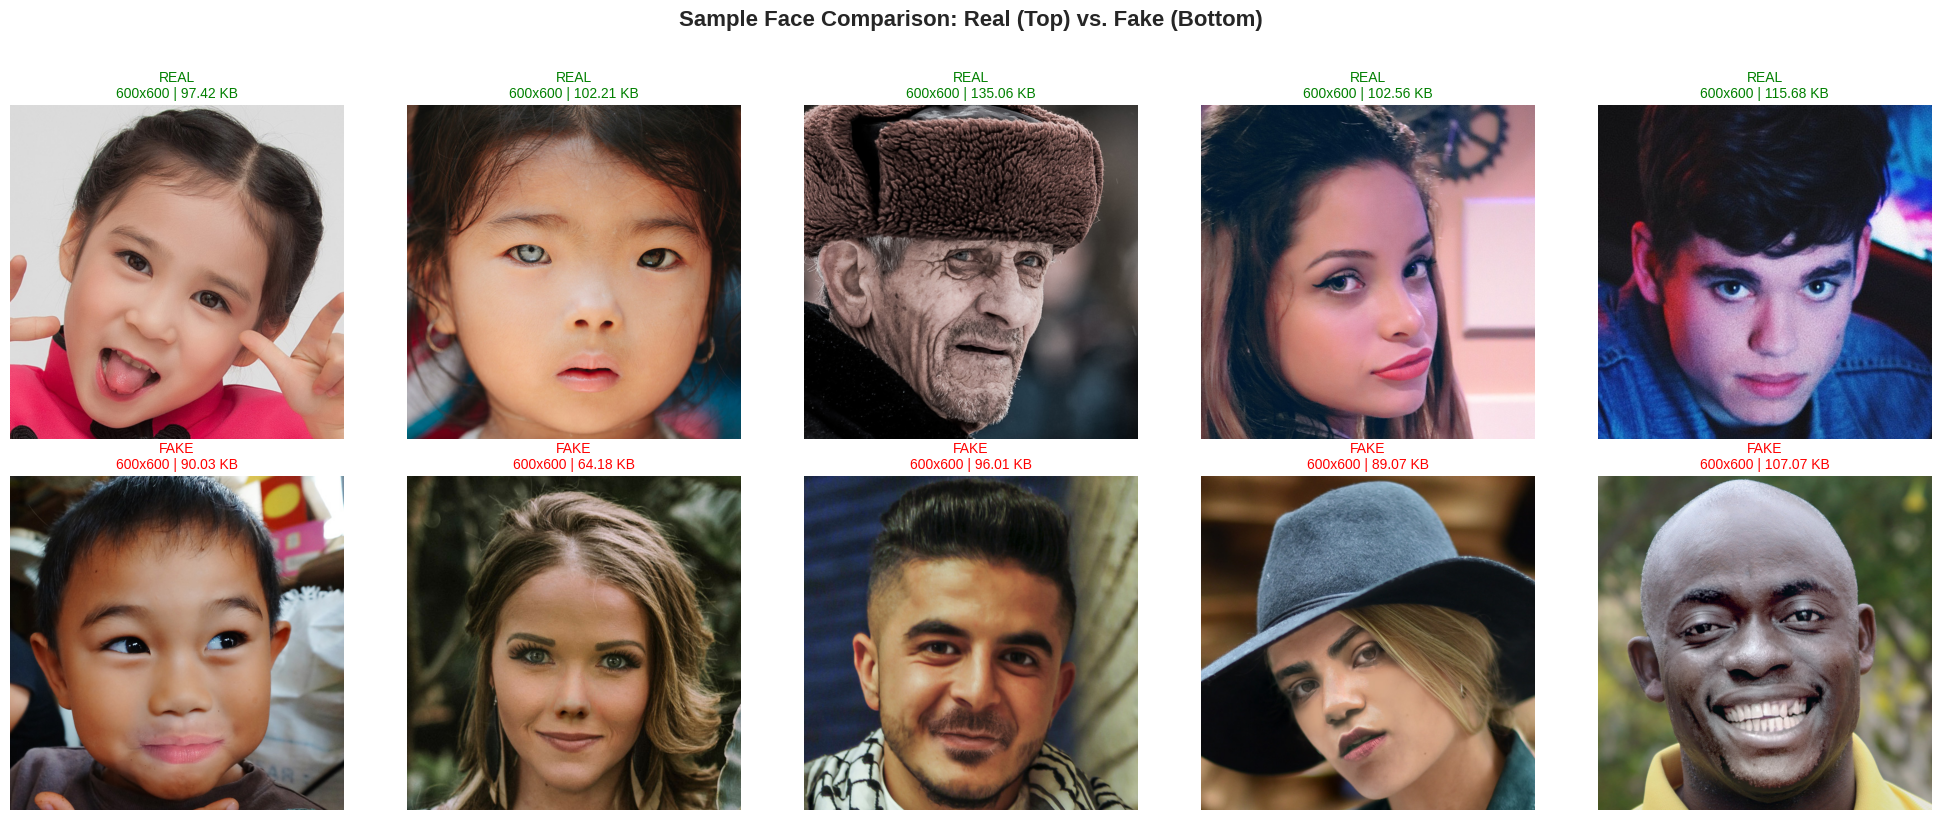

In [4]:
def plot_sample_grid(data_df, n_samples=5):
    real_samples = data_df[data_df["label"] == "Real"].sample(min(n_samples, len(data_df[data_df["label"] == "Real"])))
    fake_samples = data_df[data_df["label"] == "Fake"].sample(min(n_samples, len(data_df[data_df["label"] == "Fake"])))
    
    fig, axes = plt.subplots(2, n_samples, figsize=(4 * n_samples, 8))
    
    # Plot Real face samples
    for i, (_, row) in enumerate(real_samples.iterrows()):
        img = Image.open(row["filepath"]).convert("RGB")
        axes[0, i].imshow(img)
        axes[0, i].set_title(f"REAL\n{row['width']}x{row['height']} | {row['file_size_kb']} KB", fontsize=10, color="green")
        axes[0, i].axis("off")
        
    # Plot Fake face samples
    for i, (_, row) in enumerate(fake_samples.iterrows()):
        img = Image.open(row["filepath"]).convert("RGB")
        axes[1, i].imshow(img)
        axes[1, i].set_title(f"FAKE\n{row['width']}x{row['height']} | {row['file_size_kb']} KB", fontsize=10, color="red")
        axes[1, i].axis("off")
        
    plt.suptitle("Sample Face Comparison: Real (Top) vs. Fake (Bottom)", fontsize=16, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

plot_sample_grid(df, n_samples=5)

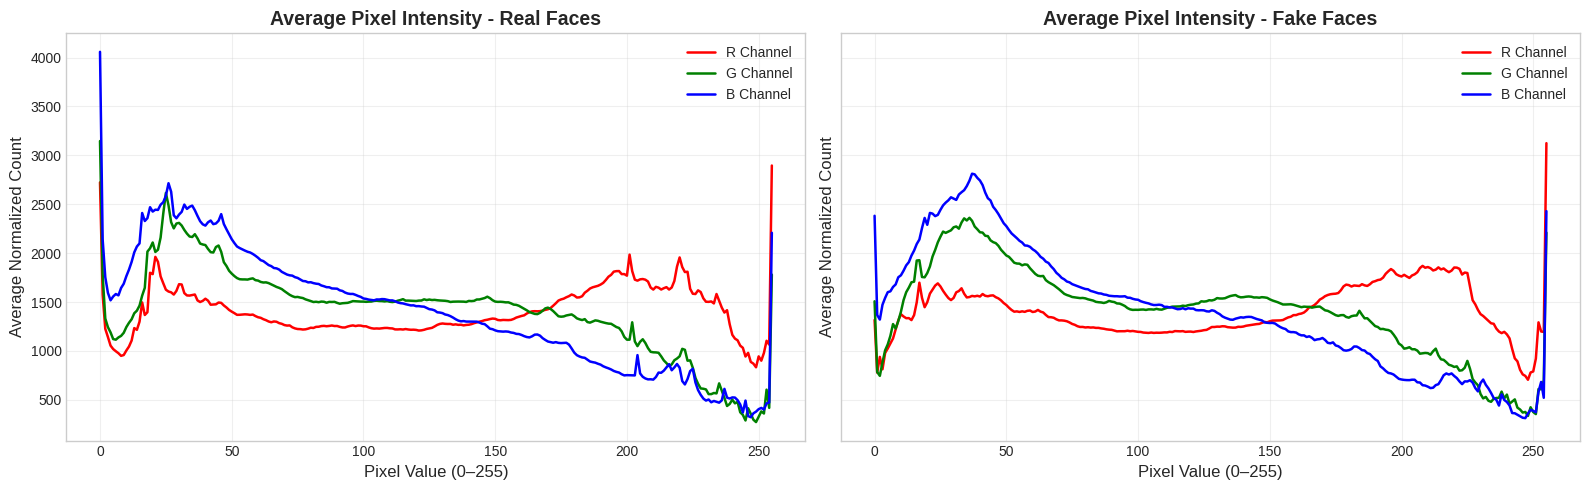

In [8]:
def plot_color_histograms(data_df, max_samples=300):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
    colors = ('r', 'g', 'b')
    
    for idx, label in enumerate(["Real", "Fake"]):
        sub_df = data_df[data_df["label"] == label]
        sample_files = sub_df["filepath"].sample(min(max_samples, len(sub_df)), random_state=42)
        
        channel_hists = {c: [] for c in colors}
        
        for fp in sample_files:
            img = cv2.imread(fp)
            if img is None:
                continue
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            
            for i, col in enumerate(colors):
                hist = cv2.calcHist([img], [i], None, [256], [0, 256])
                channel_hists[col].append(hist.flatten())
                
        for col in colors:
            mean_hist = np.mean(channel_hists[col], axis=0)
            axes[idx].plot(mean_hist, color=col, label=f'{col.upper()} Channel', linewidth=1.8)
            
        axes[idx].set_title(f"Average Pixel Intensity - {label} Faces", fontsize=14, fontweight="bold")
        axes[idx].set_xlabel("Pixel Value (0–255)", fontsize=12)
        axes[idx].set_ylabel("Average Normalized Count", fontsize=12)
        axes[idx].legend()
        axes[idx].grid(True, alpha=0.3)
        
    plt.tight_layout()
    plt.show()

plot_color_histograms(df, max_samples=300)

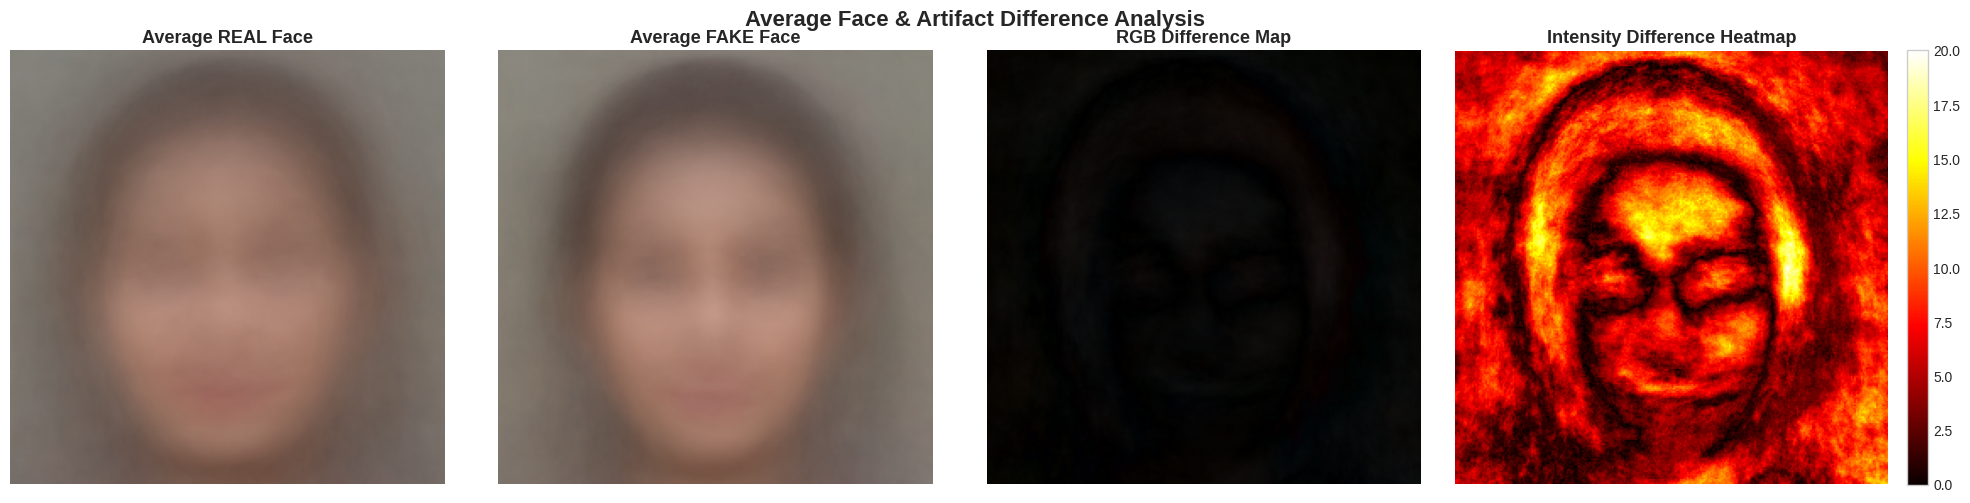

In [9]:
def compute_mean_images(data_df, target_size=(256, 256), max_samples=500):
    means = {}
    
    for label in ["Real", "Fake"]:
        sub_df = data_df[data_df["label"] == label]
        samples = sub_df["filepath"].sample(min(max_samples, len(sub_df)), random_state=42)
        
        accumulator = np.zeros((*target_size, 3), dtype=np.float64)
        valid_count = 0
        
        for fp in samples:
            img = cv2.imread(fp)
            if img is not None:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img_resized = cv2.resize(img, target_size)
                accumulator += img_resized.astype(np.float64)
                valid_count += 1
                
        means[label] = (accumulator / valid_count).astype(np.uint8)
        
    return means["Real"], means["Fake"]

# Calculate mean faces and absolute difference map
mean_real, mean_fake = compute_mean_images(df, target_size=(256, 256), max_samples=500)
diff_map = np.abs(mean_real.astype(np.int16) - mean_fake.astype(np.int16)).astype(np.uint8)
diff_gray = cv2.cvtColor(diff_map, cv2.COLOR_RGB2GRAY)

# Visualization
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(mean_real)
axes[0].set_title("Average REAL Face", fontsize=13, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(mean_fake)
axes[1].set_title("Average FAKE Face", fontsize=13, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(diff_map)
axes[2].set_title("RGB Difference Map", fontsize=13, fontweight="bold")
axes[2].axis("off")

im = axes[3].imshow(diff_gray, cmap="hot")
axes[3].set_title("Intensity Difference Heatmap", fontsize=13, fontweight="bold")
axes[3].axis("off")
plt.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

plt.suptitle("Average Face & Artifact Difference Analysis", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()